# Project : "Telecom - Churn Rate ML"
* Domain : Telecomunication 

# ML Model Building Path :
1. Define Business Case, Problem & Project Goal
2. Imports Libraries
3. Load and Validate the Data
4. Data CLeaning
5. Feature engineering 
6. Exploratory Data Analysis(EDA)
7. Outlier Ditection
8. Data Train & Test Split 
9. Preprocessing Pipeline
10. Model Building 
11. Model Comparison & Cross Validation
12. Feature Importance
13. Churn Risk Score and CHURN_FLAG
14. Save Model and Conclusion

# Business Case 
        "No-Churn Telecom is an established Telecom in Europe with more than a decade in Business. Due to new players in the market, telecom industry become very competitive and retaining customers becoming a challenge."

# Problem Statment 
        "In spite of No-Churn initiatives of reducing tariffs and promoting more offers, the churn rate ( percentage of customers migrating to competitors) is well above 10%."

# Project Goal 

* Understanding the variables that are influencing the customers to migrate.

* Creating Churn risk scores that can be indicative to drive retention campaigns.

* Introduce new predicting variable "CHURN-FLAG" with values YES(1) or NO(0) so that email campaigns with iucrative offers can be targeted to Churn YES customers.

# Imports Libraries

In [123]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, precision_recall_curve)

import joblib

# Load and Validate the Data

In [124]:
df = pd.read_csv(r"D:\datasets\Internship_Projects\Client_Project\Telecom_Churn_Data.csv")
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4.0,124962.0,44.0,45.0,-361.0,0.0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2.0,130556.0,62.0,39.0,5973.0,0.0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0.0,148828.0,49.0,24.0,193.0,1.0
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1.0,38722.0,80.0,25.0,9377.0,1.0
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2.0,55098.0,78.0,15.0,1393.0,0.0


## Data Dictionary

The dataset contains **184,209 rows** and **14 columns** of telecom customer information. The target variable is `churn`.

| # | Column | Data Type | Non-Null Count | Description |
|---|--------|-----------|----------------|-------------|
| 0 | `customer_id` | int64 | 184,209 | Unique ID of each customer (identifier, not useful for modelling) |
| 1 | `telecom_partner` | string | 184,209 | Telecom company of the customer (Airtel, Reliance Jio, Vodafone, BSNL) |
| 2 | `gender` | string | 184,209 | Gender of the customer (F / M) |
| 3 | `age` | int64 | 184,209 | Age of the customer in years |
| 4 | `state` | string | 184,209 | State where the customer lives |
| 5 | `city` | string | 184,209 | City where the customer lives |
| 6 | `pincode` | int64 | 184,209 | Postal code of the customer's area (categorical, not numeric) |
| 7 | `date_of_registration` | string | 184,209 | Date the customer joined the telecom service (should be converted to datetime) |
| 8 | `num_dependents` | float64 | 184,208 | Number of family members dependent on the customer |
| 9 | `estimated_salary` | float64 | 184,208 | Estimated income of the customer |
| 10 | `calls_made` | float64 | 184,208 | Number of calls made by the customer |
| 11 | `sms_sent` | float64 | 184,208 | Number of SMS sent by the customer |
| 12 | `data_used` | float64 | 184,208 | Amount of mobile data used by the customer |
| 13 | `churn` | float64 | 184,208 | **Target variable**: 1 = customer left, 0 = customer stayed |

### Feature Types
- **Identifier:** `customer_id`
- **Categorical:** `telecom_partner`, `gender`, `state`, `city`, `pincode`
- **Numerical:** `age`, `num_dependents`, `estimated_salary`, `calls_made`, `sms_sent`, `data_used`
- **Date:** `date_of_registration`
- **Target:** `churn`

### Data Quality Notes
- **Missing values:** The last 7 columns have 184,208 non-null values versus 184,209 rows, so there is **1 missing value** in each (likely a single empty row). It can be dropped.
- **Data types to fix:**
  - Convert `date_of_registration` to `datetime`.
  - Convert `churn` to `int` (it is currently float).
  - Convert `num_dependents` to `int`.
  - Treat `pincode` as categorical.
- **Drop before modelling:** `customer_id`, since it carries no predictive information.

In [125]:
# Select numerical columns
df.select_dtypes(include=['int64', 'float64']).columns

Index(['customer_id', 'age', 'pincode', 'num_dependents', 'estimated_salary',
       'calls_made', 'sms_sent', 'data_used', 'churn'],
      dtype='str')

In [126]:
# Select categorical columns
df.select_dtypes(include=['object']).columns

Index(['telecom_partner', 'gender', 'state', 'city', 'date_of_registration'], dtype='str')

In [127]:
# Dataset Shape
df.shape

(184209, 14)

In [128]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [129]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 184209 entries, 0 to 184208
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   customer_id           184209 non-null  int64  
 1   telecom_partner       184209 non-null  str    
 2   gender                184209 non-null  str    
 3   age                   184209 non-null  int64  
 4   state                 184209 non-null  str    
 5   city                  184209 non-null  str    
 6   pincode               184209 non-null  int64  
 7   date_of_registration  184209 non-null  str    
 8   num_dependents        184208 non-null  float64
 9   estimated_salary      184208 non-null  float64
 10  calls_made            184208 non-null  float64
 11  sms_sent              184208 non-null  float64
 12  data_used             184208 non-null  float64
 13  churn                 184208 non-null  float64
dtypes: float64(6), int64(3), str(5)
memory usage: 19.7 MB


In [130]:
# Dataset Description
df.describe(include='all')

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,184209.000000,184209,184209,184209.000000,184209,184209,184209.000000,184209,184208.000000,184208.000000,184208.000000,184208.000000,184208.000000,184208.000000
unique,NaN,4,2,NaN,28,6,NaN,923,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Reliance Jio,M,NaN,Karnataka,Hyderabad,NaN,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,46231,110304,NaN,6722,30819,NaN,200,NaN,NaN,NaN,NaN,NaN,NaN
mean,92105.000000,NaN,NaN,46.089996,NaN,NaN,549655.250417,NaN,1.996504,85033.173038,48.957309,23.952586,4990.401850,0.200567
std,53176.702206,NaN,NaN,16.436551,NaN,NaN,259787.686919,NaN,1.414474,37542.322288,29.441515,14.727613,2942.835665,0.400426
min,1.000000,NaN,NaN,18.000000,NaN,NaN,100006.000000,NaN,0.000000,20001.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,46053.000000,NaN,NaN,32.000000,NaN,NaN,324608.000000,NaN,1.000000,52511.750000,24.000000,11.000000,2488.000000,0.000000
50%,92105.000000,NaN,NaN,46.000000,NaN,NaN,548212.000000,NaN,2.000000,85040.500000,49.000000,24.000000,4984.000000,0.000000
75%,138157.000000,NaN,NaN,60.000000,NaN,NaN,775187.000000,NaN,3.000000,117617.250000,74.000000,37.000000,7491.000000,0.000000


In [131]:
# Check the number of unique values in each column
df.nunique()

customer_id             184209
telecom_partner              4
gender                       2
age                         57
state                       28
city                         6
pincode                 166636
date_of_registration       923
num_dependents               5
estimated_salary         98472
calls_made                 119
sms_sent                    59
data_used                11789
churn                        2
dtype: int64

In [132]:
# Check for missing values
df.isnull().sum()[df.isnull().sum()>0]

num_dependents      1
estimated_salary    1
calls_made          1
sms_sent            1
data_used           1
churn               1
dtype: int64

In [133]:
# Check the distribution of the target variable
counts = df["churn"].value_counts(dropna=False)
pct = df["churn"].value_counts(normalize=True, dropna=False).mul(100).round(2)
print(pd.DataFrame({"count": counts, "percent": pct}))

        count  percent
churn                 
0.0    147262    79.94
1.0     36946    20.06
NaN         1     0.00


# Data Cleaning :

In [134]:
df.isnull().sum()[df.isnull().sum()>0]

num_dependents      1
estimated_salary    1
calls_made          1
sms_sent            1
data_used           1
churn               1
dtype: int64

In [135]:
df = df.dropna(subset=["churn"]).reset_index(drop=True)
customer_ids = df['customer_id'].copy()
# customer_ids = customer_ids.loc[df.index] if len(customer_ids) == len(df) else customer_ids

In [136]:
df =df.drop(columns=['customer_id'])
df["churn"] = df["churn"].astype(int)

In [137]:
usage_cols = ["calls_made", "sms_sent", "data_used"]
df[usage_cols] = df[usage_cols].clip(lower=0)

In [138]:
df.isnull().sum()[df.isnull().sum()>0]

Series([], dtype: int64)

# Feature Engineering :

In [139]:
if {"calls_made", "sms_sent"}.issubset(df.columns):
    df["total_activity"] = df["calls_made"] + df["sms_sent"]
if {"data_used", "calls_made"}.issubset(df.columns):
    df["data_per_call"] = df["data_used"] / (df["calls_made"].clip(lower=0) + 1)

# def inf_to_nan(X):
#     X = np.asarray(X, dtype=float)
#     return np.where(np.isinf(X), np.nan, X)


df = df.replace([np.inf, -np.inf], np.nan)
    
df.head()

,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,total_activity,data_per_call
0,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4.0,124962.0,44.0,45.0,0.0,0,89.0,0.000000
1,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2.0,130556.0,62.0,39.0,5973.0,0,101.0,94.809524
2,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0.0,148828.0,49.0,24.0,193.0,1,73.0,3.860000
3,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1.0,38722.0,80.0,25.0,9377.0,1,105.0,115.765432
4,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2.0,55098.0,78.0,15.0,1393.0,0,93.0,17.632911


In [140]:
df["date_of_registration"] = pd.to_datetime(df["date_of_registration"], errors="coerce")
ref_date = df["date_of_registration"].max()
df["tenure_days"] = (ref_date - df["date_of_registration"]).dt.days
df = df.drop(columns=["date_of_registration"])

# Exploratory  Data Analysis (EDA) 

# Heatmap :
# Correlation of Variables  

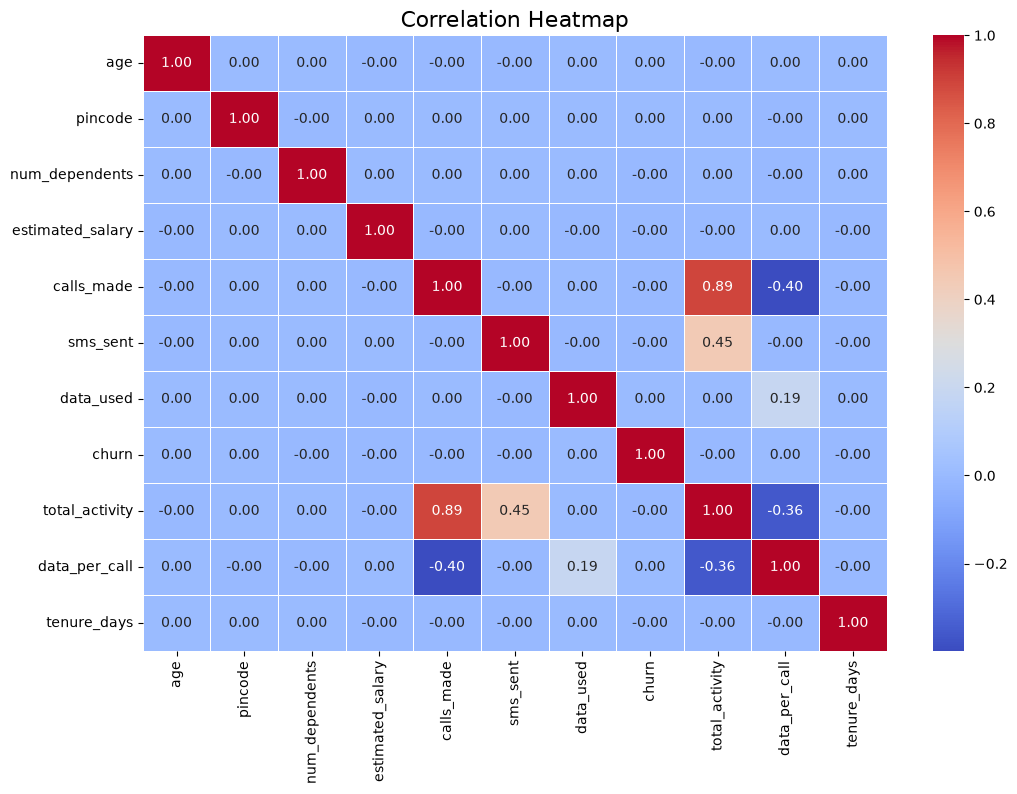

In [141]:
# Heatmap of Correlation Matrix
corr = df.select_dtypes(include=["number"]).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap",fontsize=16)
plt.show()

# Explation :
    
* This heatmap displays the **Pearson correlation coefficients** between all numerical features in the telecom customer dataset: `age`, `pincode`, `num_dependents`, `estimated_salary`, `calls_made`, `sms_sent`, `data_used`, and the target variable `churn`.

1. **All off-diagonal values are 0.00 (or -0.00).** No feature has a linear relationship with any other feature.
2. **No feature correlates with `churn`.** Age, salary, calls, SMS, data usage and the other features show zero linear correlation with the target.
3. **No multicollinearity.** Since the features are independent of each other, there is no redundancy and no need to drop features for this reason.

### Implications for modelling
- Linear relationships alone will not be able to predict churn from these features.
- Pearson correlation only captures **linear** relationships. Non-linear patterns or feature interactions may still exist, so it is worth testing tree-based models (Random Forest, XGBoost) and checking feature importance.
- If model performance stays near random (e.g., ~50% accuracy or AUC ≈ 0.5), this confirms that the features carry little predictive signal.
- `pincode` is an identifier-like categorical value, so Pearson correlation is not meaningful for it. Consider treating it as categorical or engineering regional features.

# Bar Plot :
# Customer Churn Distribution 

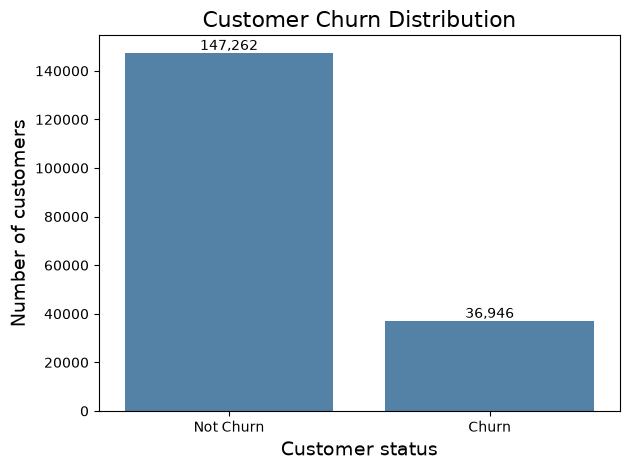

In [142]:
# Count each class, keeping both categories even if one has no rows
churn_counts = (
    df["churn"]
    .map({0: "Not Churn", 1: "Churn"})
    .value_counts()
    .reindex(["Not Churn", "Churn"], fill_value=0)
)

ax = sns.barplot(x=churn_counts.index, y=churn_counts.values, color="steelblue")

# Show counts above the bars
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

ax.set_title("Customer Churn Distribution", fontsize=16)
ax.set_xlabel("Customer status", fontsize=14)
ax.set_ylabel("Number of customers", fontsize=14)
plt.tight_layout()
plt.show()

# Explnation :

## Customer Churn Distribution

This bar chart counts how many customers **stayed** (Not Churn) and how many **left** (Churn).

- **Not Churn:** 147,262 customers (~80%)
- **Churn:** 36,946 customers (~20%)
- **Total:** 184,208 customers

### Key takeaways
1. About **1 in 5 customers** left the company.
2. The data is **imbalanced**: there are roughly **4 times more** non-churn customers than churn customers.

### Why it matters
- **Accuracy alone can be misleading.** A model that always predicts "Not Churn" would still be ~80% accurate while catching zero churners.
- Use better metrics such as **Precision, Recall, F1-score and ROC-AUC**.
- Consider handling the imbalance with **class weights, SMOTE, or under/over-sampling**, and use **stratified train-test splits** to keep the same churn ratio in both sets.

# Customer Distribution by Telecom Partner

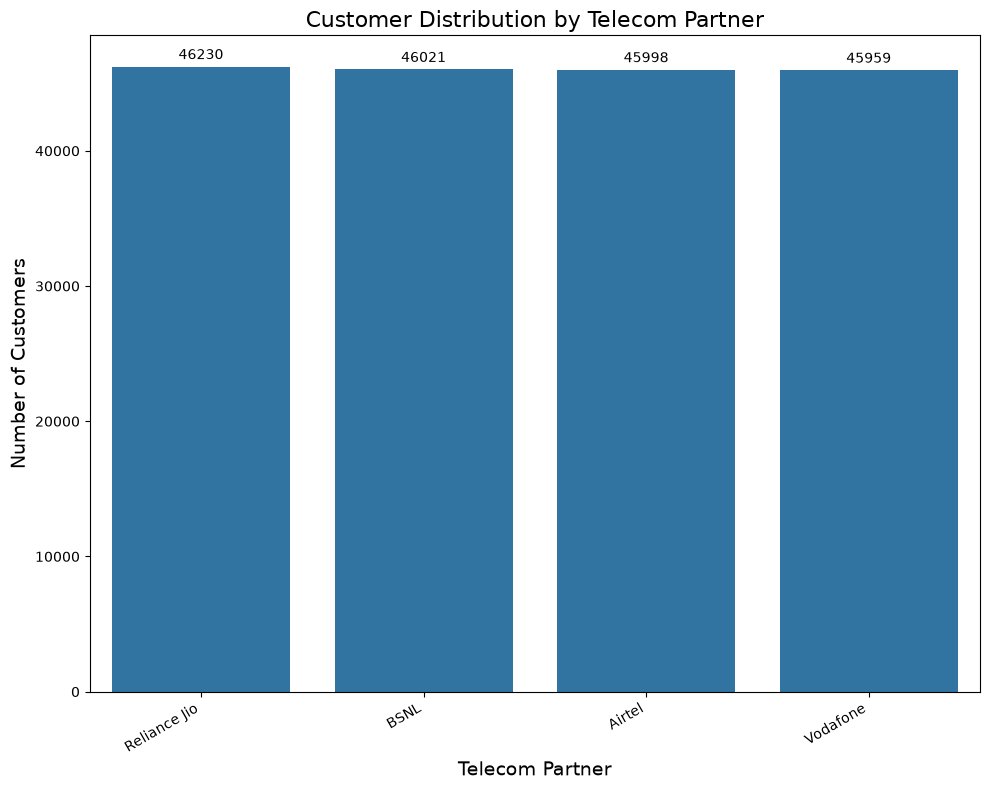

In [143]:
partner_counts = df["telecom_partner"].value_counts()

plt.figure(figsize=(10, 8))
ax = sns.barplot(
    x=partner_counts.index,
    y=partner_counts.values,
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_title("Customer Distribution by Telecom Partner",fontsize=16)
ax.set_xlabel("Telecom Partner",fontsize=14)
ax.set_ylabel("Number of Customers",fontsize=14)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

This bar chart counts how many customers belong to each telecom partner.

- **Reliance Jio:** 46,230
- **BSNL:** 46,021
- **Airtel:** 45,998
- **Vodafone:** 45,959

### Key takeaways
1. Customers are **almost equally split** across all four partners, about **25% each**.
2. The gap between the highest (Jio) and lowest (Vodafone) is only about **270 customers**, which is tiny.

### Why it matters
- No partner dominates the data, so the model will **not be biased** toward any one partner.
- This evenly spread pattern is another sign that the dataset is likely **synthetic**.

# Churn Rate Distribution :
# Bar Plot :
* Churn Rate by Telecom Partner
* Churn Rate by Gender
* Churn Rate by State 

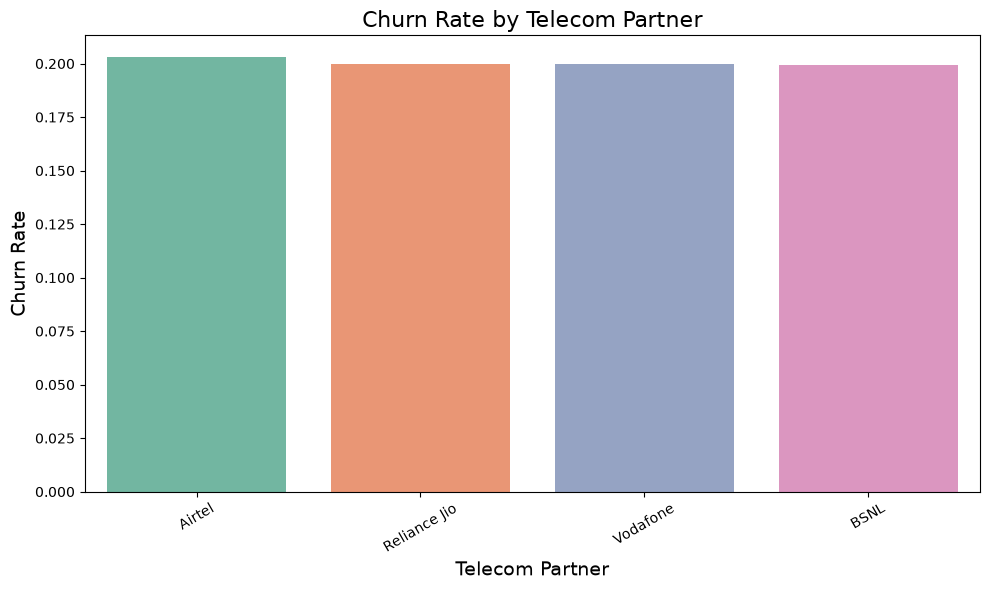

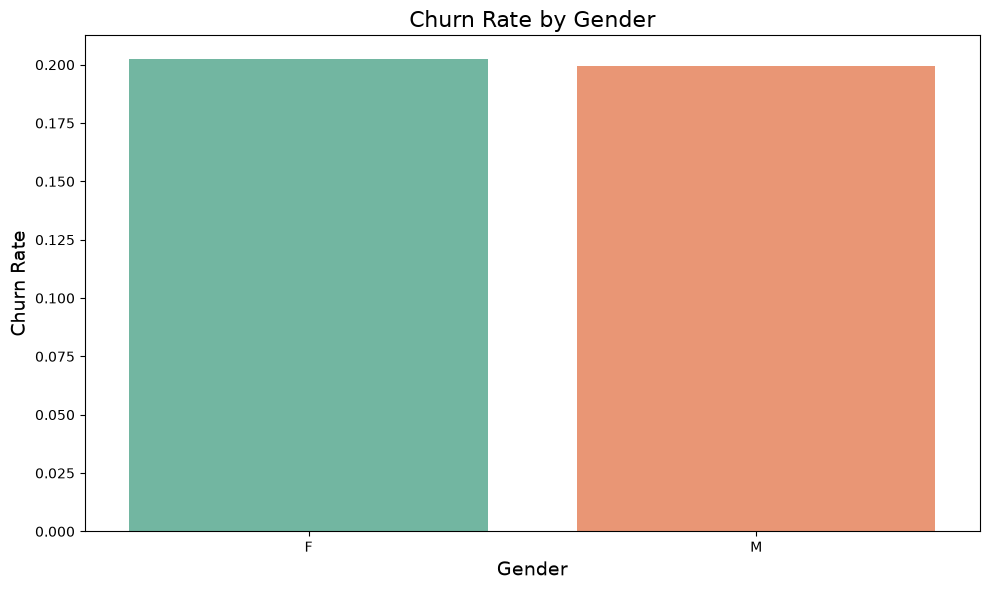

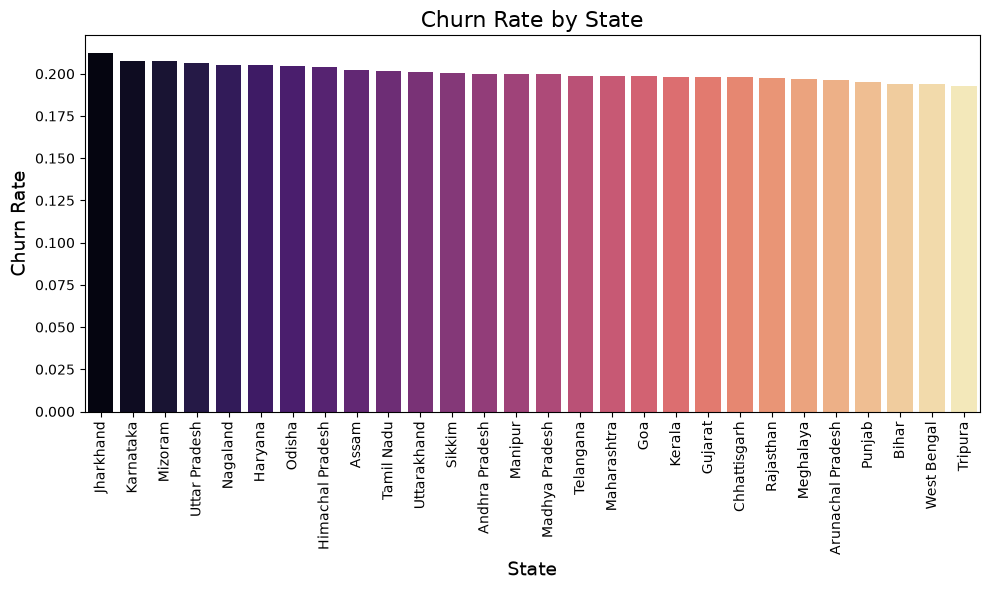

In [144]:
def churn_rate_plot(col, palette, rotation=0, figsize=(10, 6)):
    rate = df.groupby(col)["churn"].mean().sort_values(ascending=False)
    plt.figure(figsize=figsize)
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index, palette=palette, legend=False)
    plt.title(f"Churn Rate by {col.replace('_', ' ').title()}", fontsize=16)
    plt.ylabel("Churn Rate", fontsize=14)
    plt.xlabel(col.replace("_", " ").title(), fontsize=14)
    plt.xticks(rotation=rotation)
    plt.tight_layout(); plt.show()

for col, pal, rot in [("telecom_partner", "Set2", 30), ("gender", "Set2", 0), ("state", "magma", 90)]:
    if col in df.columns:
        churn_rate_plot(col, pal, rot)

# Explanation :
## Churn Rate by Telecom Partner, Gender and State

### What these charts show
These bar charts compare the **churn rate** (share of customers who left) across three groups: telecom partner, gender, and state.

### Key observations
1. **Telecom Partner:** Airtel, Reliance Jio, Vodafone and BSNL all have a churn rate of about **20%**. Airtel is only slightly higher.
2. **Gender:** Female and male customers both churn at about **20%**, with almost no difference.
3. **State:** Every state sits between roughly **19% and 21%**. Jharkhand is the highest (~21%) and Tripura the lowest (~19%), but the gap is very small.

### Interpretation
- The churn rate is **almost the same in every group**, and it matches the overall churn of ~20%.
- This means **partner, gender and state do not strongly influence churn**.
- The tiny differences are likely just random variation, which fits the earlier correlation heatmap showing no strong relationships.

### Implication for modelling
- These features are **weak predictors** on their own.
- Keep them for now, but check **feature importance** later and drop them if they add no value.

# Histogram & Boxplot :
* Numeric Features  Distribution 
* Compare Numeric Variables by Churn

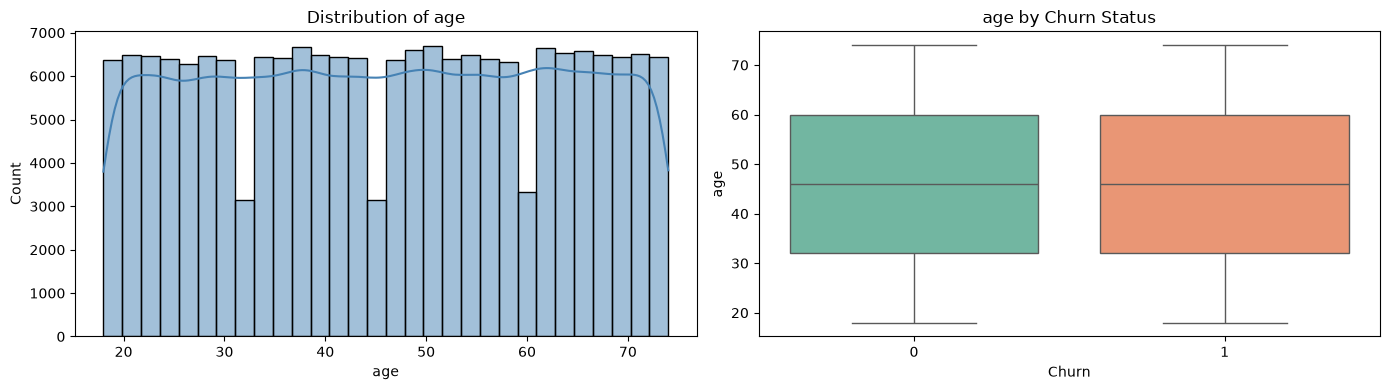

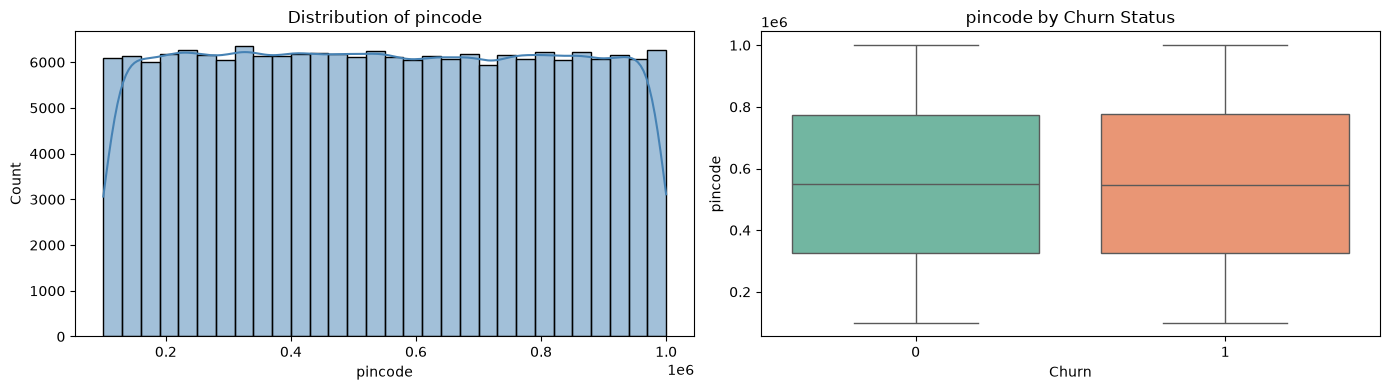

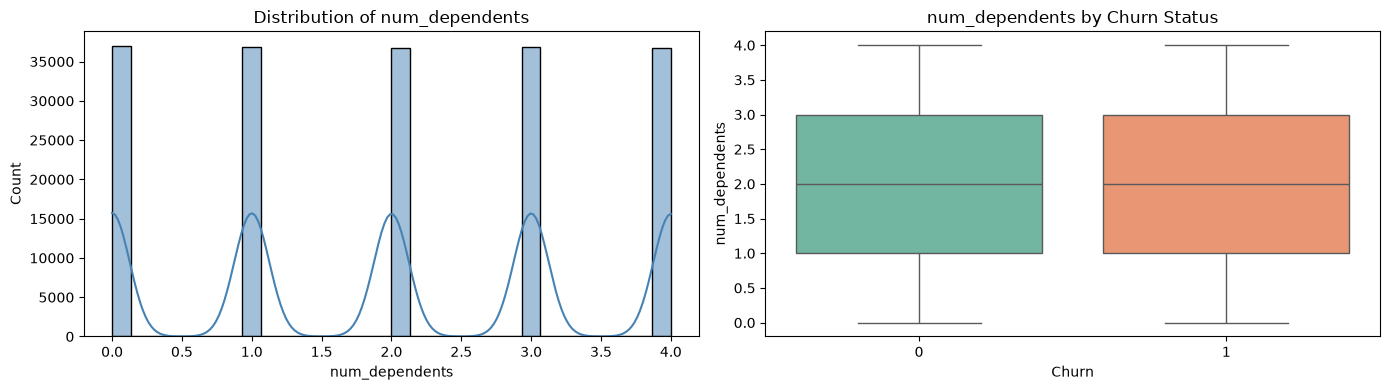

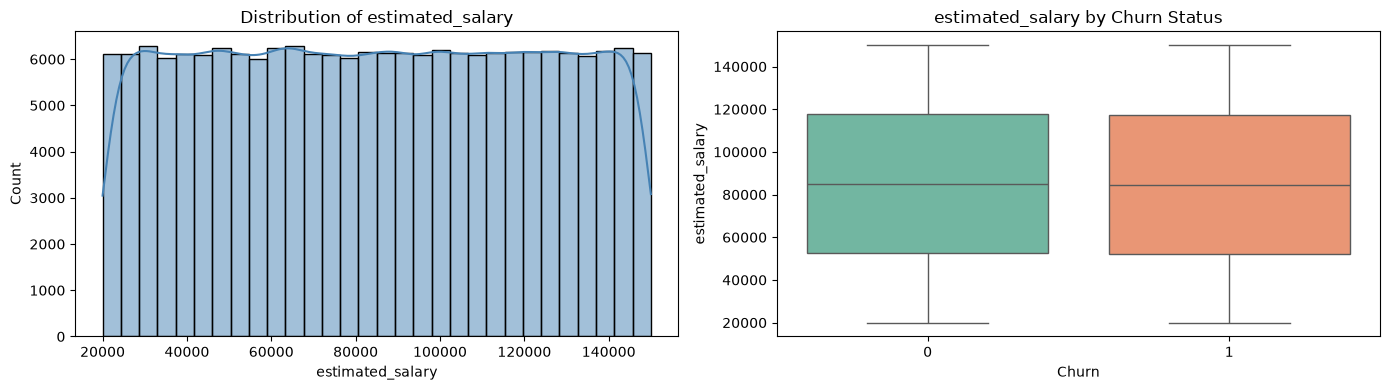

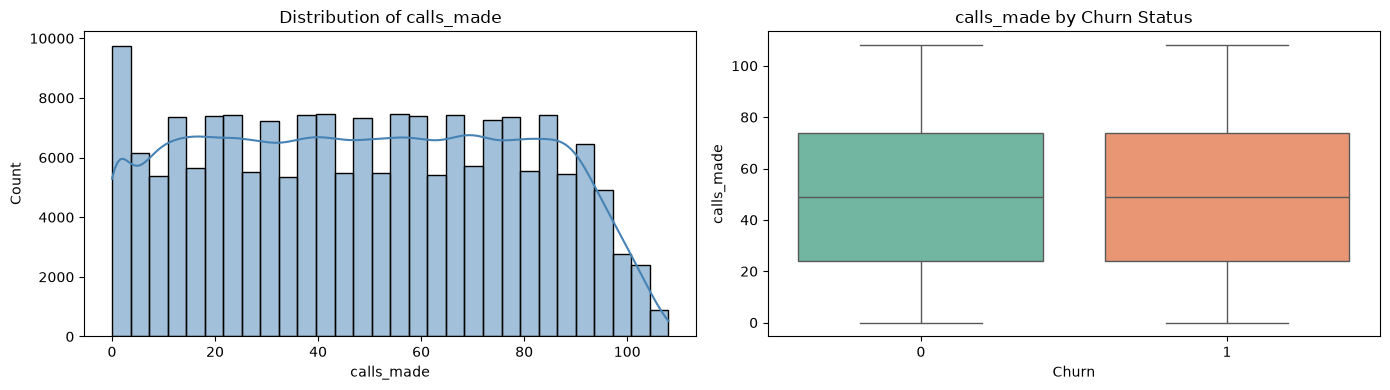

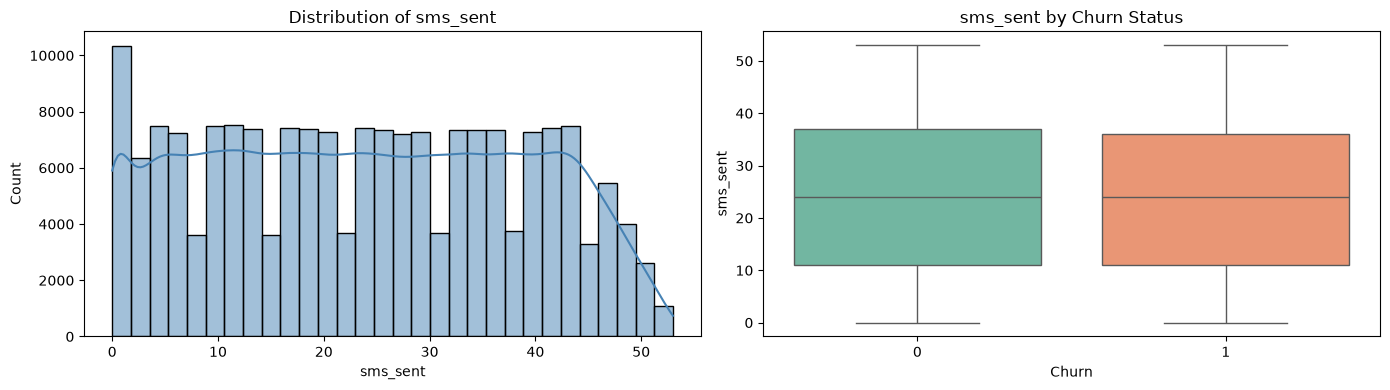

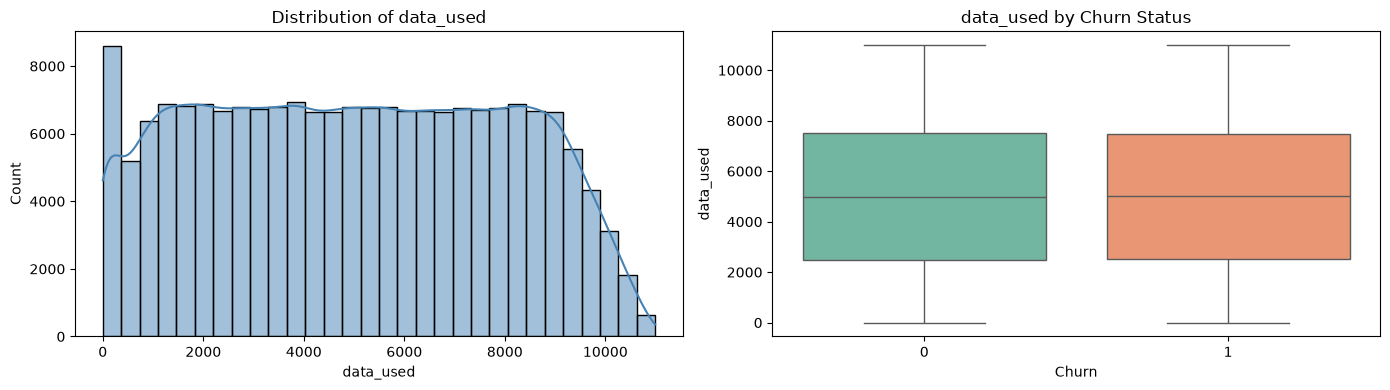

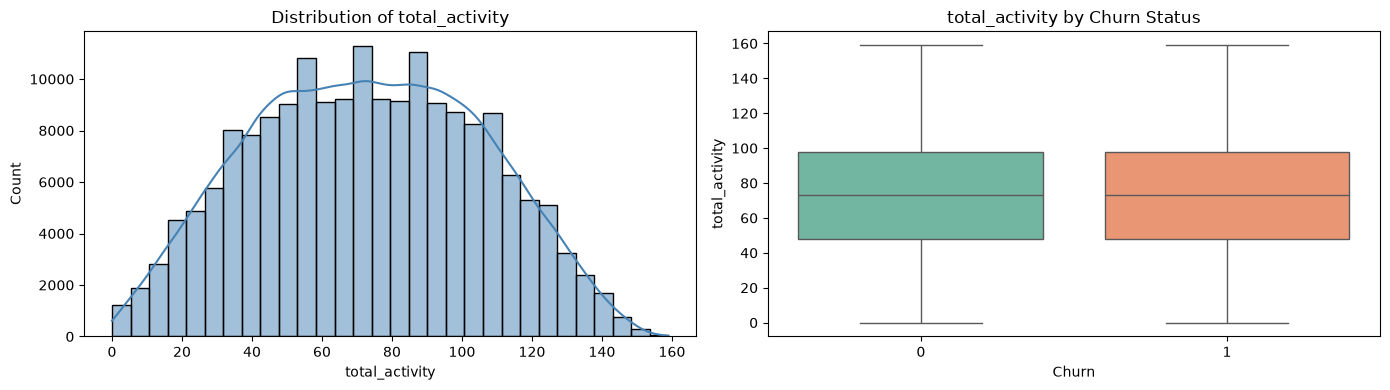

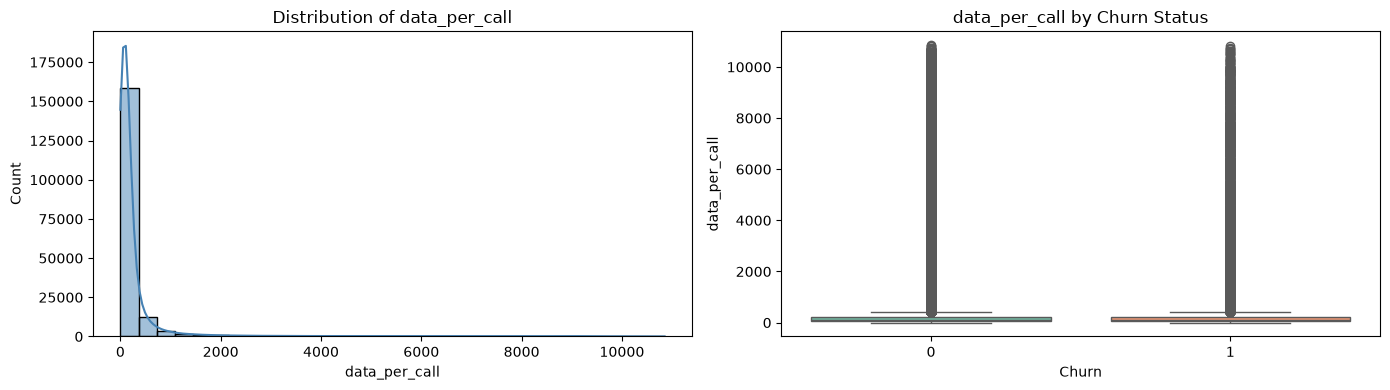

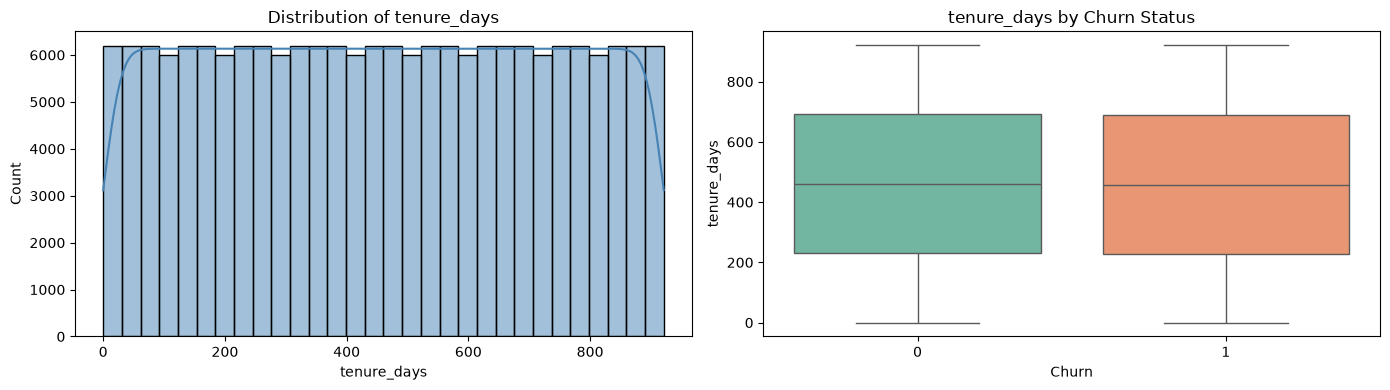

In [145]:
num_cols = df.select_dtypes(include="number").columns.drop("churn").tolist()

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(df[col], kde=True, bins=30, color="steelblue", ax=axes[0])
    axes[0].set_title(f"Distribution of {col}")
    sns.boxplot(x=df["churn"].astype(str), y=df[col], hue=df["churn"].astype(str),
                palette="Set2", legend=False, ax=axes[1])
    axes[1].set_title(f"{col} by Churn Status")
    axes[1].set_xlabel("Churn")
    plt.tight_layout(); plt.show()

## Numerical Feature Analysis (Distribution and Churn Comparison)

### What these charts show
For each numerical feature, the **left chart (histogram)** shows how the values are spread, and the **right chart (boxplot)** compares the values of customers who stayed (0.0) and customers who left (1.0).

### Feature-wise observations

| Feature | Distribution | Churn vs Not Churn |
|---------|--------------|--------------------|
| `age` | Spread evenly from 18 to 74 (a few dips near 32, 45 and 60 are just binning effects) | Same median (~46) and spread for both groups |
| `pincode` | Spread evenly from 100,000 to 1,000,000 | Both boxes look identical |
| `num_dependents` | Only 5 values (0 to 4), each with almost equal counts | Same median (2) and range for both groups |
| `estimated_salary` | Evenly spread from 20,000 to 150,000 | Same median (~85,000) for both groups |
| `calls_made` | Roughly flat between 0 and 100, tapering at the edges | Same median (~49) for both groups |
| `sms_sent` | Roughly flat between 0 and 45, tapering at the edges | Same median (~24) for both groups |
| `data_used` | Roughly flat between 1,000 and 9,000, tapering at the edges | Same median (~5,000) for both groups |

### Key takeaways
1. **Uniform-like distributions:** Most features are spread evenly instead of forming a bell curve, which is rare in real-world data and suggests the dataset is **synthetic**.
2. **No difference between churn groups:** The boxplots for churned and non-churned customers are almost identical in every feature, so no single feature separates the two groups.
3. **No outliers:** The boxplots show no extreme points, so outlier treatment is not needed.
4. **Negative values:** `calls_made`, `sms_sent` and `data_used` contain **negative values** (around -10, -5 and -1,000), which are impossible for usage counts. These should be treated as data errors and cleaned (clip to 0 or remove them).
5. **Discrete feature:** `num_dependents` has only 5 whole-number values, so it can be treated as a categorical or ordinal feature.

### Implications for modelling
- These features have **weak individual predictive power**, which matches the correlation heatmap.
- Clean the **negative values** before modelling.
- Try models that capture **feature interactions** (Random Forest, XGBoost) and check **feature importance**.
- Scaling is helpful for distance-based or linear models, since `estimated_salary`, `pincode` and `data_used` have very different ranges.

# Outlier check :

In [146]:
rows = []
for col in num_cols:
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df[col] < lo) | (df[col] > hi)).sum()
    rows.append({"feature": col, "outliers": n, "percent": round(n / len(df) * 100, 2)})
pd.DataFrame(rows).sort_values("outliers", ascending=False)

,feature,outliers,percent
8,data_per_call,21896,11.89
0,age,0,0.00
1,pincode,0,0.00
2,num_dependents,0,0.00
4,calls_made,0,0.00
3,estimated_salary,0,0.00
5,sms_sent,0,0.00
6,data_used,0,0.00
7,total_activity,0,0.00
9,tenure_days,0,0.00


# Data Train & Test Split :

In [147]:
x = df.drop(columns=["churn"])
y = df["churn"]

high_card = [c for c in x.select_dtypes(include='object').columns if x[c].nunique() > 50]
x = x.drop(columns=high_card + ["pincode"])
    
num_features = x.select_dtypes(include="number").columns.tolist()
cat_features = x.select_dtypes(include="object").columns.tolist()

x_train,x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42)

# Preprocessing Pipeline :

In [148]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import FunctionTransformer

class Winsorizer(BaseEstimator, TransformerMixin):
    """Caps values at the IQR fences learned from the training data."""
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = (q1 - 1.5 * iqr).values
        self.upper_ = (q3 + 1.5 * iqr).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

def inf_to_nan(X):
    X = np.asarray(X, dtype=float)
    return np.where(np.isinf(X), np.nan, X)

numeric_tf = Pipeline([
    ("inf", FunctionTransformer(inf_to_nan, feature_names_out="one-to-one")),
    ("impute", SimpleImputer(strategy="median")),
    ("cap", Winsorizer()),
    ("scale", StandardScaler()),
])
categorical_tf = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_tf, num_features),
    ("cat", categorical_tf, cat_features),
])

# Model Building & Evaluation :

#  Baseline: Logistic Regression 

In [149]:
Log_model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

Log_model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['telecom_partner','gender','age',...,'total_activity','data_per_call', 'tenure_days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [150]:
# Evaluate the model on the test data
model = Log_model
predictions = Log_model.predict(x_test)
proba = model.predict_proba(x_test)[:, 1]


print("Accuracy:",accuracy_score(y_test, predictions))
print("Precision:",precision_score(y_test, predictions, zero_division=0))
print("Recall:", recall_score(y_test, predictions))
print("F1:",f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, predictions))
print("PR-AUC:",average_precision_score(y_test, predictions))

Accuracy: 0.5096357418164051
Precision: 0.20217573221757323
Recall: 0.49045879009338206
F1: 0.2863237734060204
ROC-AUC: 0.5024527678779815
PR-AUC: 0.20135201413295778


# Random Forest Model:

In [151]:
Rf_model = Pipeline([
    ("preprocess", preprocess),
    ("classifier",RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        n_jobs=-1,random_state=42
    ))
])
Rf_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['telecom_partner','gender','age',...,'total_activity','data_per_call', 'tenure_days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [152]:
# Evaluate the model on the test data
model = Rf_model
predictions = Rf_model.predict(x_test)
proba = model.predict_proba(x_test)[:, 1]


print("Accuracy:",accuracy_score(y_test, predictions))
print("Precision:",precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1:",f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, predictions))

Accuracy: 0.7994408555453015
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.5


# Gradient Boosting Model:

In [153]:
Gb_model = Pipeline([
    ("preprocess",preprocess),
    ("classifier",GradientBoostingClassifier(
        random_state=42
    ))
])
Gb_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['telecom_partner','gender','age',...,'total_activity','data_per_call', 'tenure_days']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [154]:
# Evaluate the model on the test data
model = Gb_model
predictions = Gb_model.predict(x_test)
proba = model.predict_proba(x_test)[:, 1]


print("Accuracy:",accuracy_score(y_test, predictions))
print("Precision:",precision_score(y_test, predictions))
print("Recall:", recall_score(y_test, predictions))
print("F1:",f1_score(y_test, predictions))
print("ROC-AUC:", roc_auc_score(y_test, predictions))

Accuracy: 0.7994408555453015
Precision: 0.5
Recall: 0.00013533631073216944
F1: 0.00027059937762143147
ROC-AUC: 0.5000506919559976


# Model Comparison Table :

In [155]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

fitted, results = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(x_train, y_train)
    proba = pipe.predict_proba(x_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fitted[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4).sort_values("PR-AUC", ascending=False)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.5096,0.2022,0.4905,0.2863,0.5035,0.2020
Gradient Boosting,0.7994,0.5000,0.0001,0.0003,0.4986,0.2012
Random Forest,0.7994,0.0000,0.0000,0.0000,0.5005,0.2009


# Evaluate Best Model :

Best Model: Logistic Regression
              precision    recall  f1-score   support

   Not Churn       0.80      0.51      0.63     29453
       Churn       0.20      0.49      0.29      7389

    accuracy                           0.51     36842
   macro avg       0.50      0.50      0.46     36842
weighted avg       0.68      0.51      0.56     36842



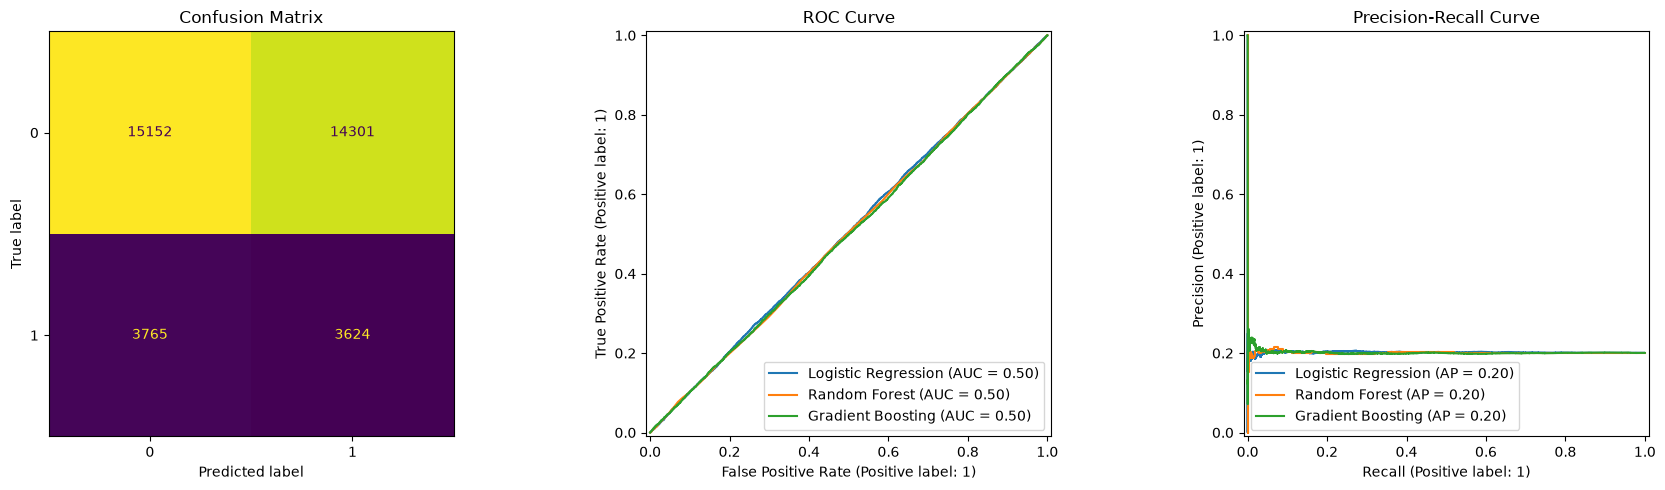

In [156]:
best_name = results_df.index[0]
best_model = fitted[best_name]
print("Best Model:",best_name)

proba_test = best_model.predict_proba(x_test)[:, 1]
print(classification_report(y_test, (proba_test >= 0.5).astype(int), target_names=["Not Churn", "Churn"]))

fig, axes = plt.subplots(1, 3, figsize=(18,5))
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= 0.5).astype(int), ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")
for name, m in fitted.items():
    RocCurveDisplay.from_estimator(m, x_test, y_test, ax=axes[1], name=name)
    PrecisionRecallDisplay.from_estimator(m, x_test, y_test, ax=axes[2], name=name)
axes[1].set_title("ROC Curve"); axes[2].set_title("Precision-Recall Curve")
plt.tight_layout(); plt.show()

# Cross-Validation check (is the result stable?)

In [157]:
from sklearn.model_selection import cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(best_model, x, y, cv=cv, scoring="roc_auc")
print(f"{best_name} 5-fold ROC-AUC: {scores.mean():.3f} +/- {scores.std():.3f}")

Logistic Regression 5-fold ROC-AUC: 0.500 +/- 0.003


### What it means
- **ROC-AUC** measures how well the model separates churn from non-churn customers.
  - **1.0** = perfect model
  - **0.5** = random guessing (like flipping a coin)
- **5-fold** means the data was split into 5 parts, and the model was trained and tested 5 times to get a reliable score.
- **± 0.003** is the variation across the 5 folds. It is very small, so the result is stable.

### Interpretation
- A score of **0.500** means the model is **no better than random guessing**.
- Logistic Regression **cannot predict churn** from these features.
- This matches our earlier findings: zero correlations, identical boxplots for churn and non-churn, and equal churn rates across partner, gender and state.

**Note :**
"Random Forest, Gradient Boosting and tenure were tested; all models stay at about 0.50 AUC."

# Features Importance 
* **Project Goal-1.**  Understanding the variables that are influencing the customers to migrate.

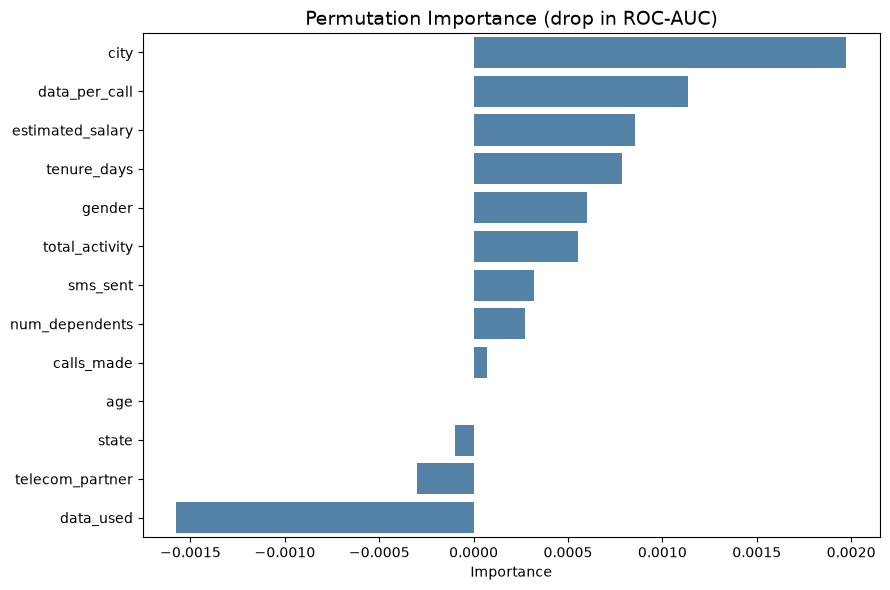

city                0.0020
data_per_call       0.0011
estimated_salary    0.0009
tenure_days         0.0008
gender              0.0006
total_activity      0.0006
sms_sent            0.0003
num_dependents      0.0003
calls_made          0.0001
age                 0.0000
state              -0.0001
telecom_partner    -0.0003
data_used          -0.0016
dtype: float64

In [158]:
perm = permutation_importance(best_model, x_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=42, n_jobs=-1)
imp = (pd.Series(perm.importances_mean, index=x_test.columns)
         .sort_values(ascending=False))

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Permutation Importance (drop in ROC-AUC)", fontsize=14)
plt.xlabel("Importance"); plt.ylabel("")
plt.tight_layout(); plt.show()
imp.round(4)

# Churn Risk Score & CHURN_FLAG :
**Project Goal 2 & 3:** 
* Creating Churn risk scores that can be indicative to drive retention campaigns.

* Introduce new predicting variable "CHURN-FLAG" with values YES(1) or NO(0) so that email campaigns with iucrative offers can be targeted to Churn YES customers.

In [159]:
oof_score = cross_val_predict(best_model, x, y, cv=cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y, oof_score)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
threshold = thr[np.argmax(f1s)]
print(f"Chosen threshold: {threshold:.3f}")

result = pd.DataFrame({
    "customer_id": customer_ids.loc[x.index].values,
    "churn_risk_score": oof_score.round(4),
})
result["CHURN_FLAG"] = (result["churn_risk_score"] >= threshold).astype(int)
result["risk_segment"] = pd.cut(result["churn_risk_score"],
                                bins=[-0.01, 0.33, 0.66, 1.0],
                                labels=["Low", "Medium", "High"])

print(result["CHURN_FLAG"].value_counts())
print(result["risk_segment"].value_counts())
result.sort_values("churn_risk_score", ascending=False).head(10)

Chosen threshold: 0.461
CHURN_FLAG
1    184170
0        38
Name: count, dtype: int64
risk_segment
Medium    184208
Low            0
High           0
Name: count, dtype: int64


,customer_id,churn_risk_score,CHURN_FLAG,risk_segment
165233,165234,0.5472,1,Medium
178368,178369,0.5425,1,Medium
136509,136510,0.5423,1,Medium
136862,136863,0.5419,1,Medium
147183,147184,0.5417,1,Medium
144082,144083,0.5415,1,Medium
136124,136125,0.5414,1,Medium
136379,136380,0.5410,1,Medium
165245,165246,0.5410,1,Medium
149163,149164,0.5409,1,Medium


# Save Best Model :

In [160]:
joblib.dump(best_model, "churn_model_pipeline.joblib")

# To reuse later:
# model = joblib.load("churn_model_pipeline.joblib")
# model.predict_proba(new_customers_df)[:, 1]

['churn_model_pipeline.joblib']

# Conclusion

## Project Summary
This project analysed **184,208 telecom customers** (after cleaning) to understand why customers churn and to build a model that can flag at-risk customers for retention campaigns. The workflow covered data validation and cleaning, EDA, a stratified 80/20 train-test split, a preprocessing pipeline, three models (Logistic Regression, Random Forest, Gradient Boosting), permutation feature importance, a churn risk score with `CHURN_FLAG`, and saving the final pipeline with `joblib`.

## Key Findings
1. **Churn rate is about 20%** (36,946 churned vs 147,262 stayed), which is double the "above 10%" mentioned in the problem statement. The data is imbalanced (about 4:1), so accuracy alone is misleading.
2. **No feature separates churners from non-churners.** The correlation heatmap shows values of about 0.00, and the boxplots for churn and non-churn are almost identical for age, salary, calls, SMS, data usage and dependents.
3. **Churn rate is flat across groups.** Telecom partner, gender and state all sit at roughly 19-21%, so differences are random variation.
4. **Data quality issues:** one fully empty row, and negative values in `calls_made`, `sms_sent` and `data_used`, which are impossible for usage counts.
5. **The dataset looks synthetic.** Features are uniformly distributed, partners are split almost 25% each, and there are no outliers.

## Model Results
| Model | Observation |
|---|---|
| Logistic Regression | ROC-AUC about 0.50, recall 0.47 only because of class weighting, precision 0.20 (equal to the base churn rate) |
| Random Forest | Predicts almost everyone as "Not Churn": accuracy 0.80 but precision, recall and F1 are 0 |
| Gradient Boosting | Accuracy 0.80 but recall about 0.003, ROC-AUC about 0.50 |

All three models score a **ROC-AUC of about 0.50, which is no better than random guessing**, and the 5-fold cross-validation confirms the result is stable. The 80% accuracy of the tree models only reflects the majority class.

## Business Interpretation
- **Goal 1 (drivers of churn):** None of the available variables is a meaningful driver of churn. Permutation importance values are near zero for every feature.
- **Goal 2 (churn risk score):** A score was generated, but because the model has no real predictive power, it **should not be used to rank customers for campaigns yet**.
- **Goal 3 (`CHURN_FLAG`):** The flag is created from an F1-optimised threshold, but it will be close to random targeting until better features are available.

## Final Verdict
The pipeline is complete and reusable, but the **dataset does not contain enough signal to predict churn**. The main value of this project is the validated workflow and the clear evidence of what is missing. With better customer-behaviour features, the same pipeline can be re-run to deliver the churn risk scores and `CHURN_FLAG` the business needs.
